# Early Prediction of Student Withdrawal
ES 678 - Aditya Gupta (24110011)

Read the complete reasoning below. Saved results can be inspected without downloading the raw data. The interaction changes an evaluation budget; it does not tune a model.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Markdown, Image
ROOT = Path.cwd()
if not (ROOT / 'config.json').exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
R = ROOT / 'results'
display(Markdown((ROOT / 'docs' / 'STUDY.md').read_text(encoding='utf-8')))

# Research reasoning and evidence

## Question and intended claim

How accurately can future withdrawal be predicted at days 14, 28 and 42? Do models
trained on an earlier offering improve on an inactivity ranking when only 10% of
eligible students can be flagged on a later offering?

One row represents a student–module–offering enrollment at a cutoff. A positive
label means withdrawal strictly after that cutoff. Pass, Distinction and academic
Fail count as non-withdrawal. Students who already withdrew are ineligible. This
is ranking for limited outreach capacity, not a diagnosis or causal intervention.

## Data and quality

The public OULAD release has 32,593 enrollment records, 22 offerings across seven
modules and 10,655,280 daily student–resource activity rows. These are enrollment
records, not 32,593 necessarily distinct people. The original archive documentation
contains a conflicting 32,953 count; use the measured CSV counts. See the data
paper and UCI citations in `AI_USE_AND_REFERENCES.md`.

We select FFF 2013J for development and FFF 2014J for test using same-season pairs,
chronology and development cohort size, never predictive performance. The raw
offerings have 2,283 and 2,365 enrollments. All 117 students appearing in both are
removed from development. Six snapshots contain:

| Day | Development N / withdrawals | Test N / withdrawals | Test prevalence |
|---|---|---|---|
| 14 | 1,890 / 302 | 1,862 / 353 | 18.96% |
| 28 | 1,874 / 286 | 1,834 / 325 | 17.72% |
| 42 | 1,846 / 258 | 1,810 / 301 | 16.63% |

The loader parses `?` as missing. It checks join-key uniqueness and matching
registration records. Five development and 26 test records fail outcome/date
consistency or registration-date validity checks, before cutoff eligibility.
These are retrospective complete-outcome exclusions, a possible selection bias.
Zero-activity students remain through enrollment-based joins. `data_audit.csv`,
`cohorts.csv`, `snapshot_diagnostics.csv` and the 48-row raw-record audit document
these checks. Public data are pseudonymized; there is no attempt at reidentification.

## Preprocessing and why it is appropriate

Background features are previous attempts, study load and highest education.
Engagement summarizes clicks, active dates, inactivity, a no-activity flag, recent
weekly clicks and their change. Submission features count non-exam submissions,
due assignments, overdue assignments and completion of due work. The exact
definitions are in `protocol.md` and the predictor allowlists in `data.py`.

At each cutoff, activity and submission records must have dates at or before it.
Pre-course activity is retained because it was observable. A deadline must be
strictly before the cutoff to count as overdue. A later submission cannot erase
an earlier overdue status. Marks are excluded because release times are unknown.
No activity becomes zero clicks/active days plus a separate indicator; inactivity
for these students uses a documented finite proxy, not a measured last-login date.
When nothing is due, submission rate is undefined, not evidence of poor completion.

Inside each training fold, numeric missing values receive training medians;
entirely missing numeric columns are retained with zero fill. Education receives
mode imputation and one-hot encoding, with unseen levels ignored. Logistic
regression uses standardized numeric inputs so regularization is comparable
across units. Trees do not require scaling. Validation/test data never determine
these learned transformations. IDs, outcomes, unregistration dates and warning
days are excluded from predictors even though they remain in audit datasets.

## Baselines and models

Random ranking measures no-information selection: expected recall is k/N and
expected precision is prevalence. One seeded realization is also reported.
Inactivity ranks never-active students first, then time since last activity;
ties use seeded, outcome-independent random ordering. This tests added value
beyond a cheap, understandable rule. A constant development-prevalence prediction
is the probability baseline for Brier score.

Regularized logistic regression estimates log-odds as a linear function of encoded
features; it is a restrained, interpretable starting point. Its L2 strength uses
C in {0.1, 1, 10}. Histogram gradient boosting models nonlinearities/interactions,
using 100 iterations, learning rate 0.05, leaves in {7, 15}, L2 in {1, 10}, and no
early stopping. We do not assume more complexity is better. Each cutoff and feature
group has its own fitted pipeline: 3 × 4 × 2 = 24 models, with 420 CV fits plus refits.

## Evaluation and statistical reasoning

We tune mean recall at the 10% budget using five stratified student-grouped folds
within 2013J, seed 678. Final models refit on all eligible development rows. Test
students are unseen, and all models are chosen before scoring 2014J. Exact IDs
and validation-fold assignments are exported to `results/splits/`.

Chronology assumes outcomes available 30 days after the earlier course finishes.
Using conservative month bounds, that date is 2014-08-25, before the earliest
day-14 test date of 2014-10-15. Actual release timestamps are unavailable; this is
an explicit assumption, not verified administrative history.

For N eligible students, k=floor(0.10N). Recall is TP / all withdrawals; precision
is TP / k. At a fixed budget and prevalence, precision = recall × prevalence / (k/N),
so these are complementary operational descriptions, not independent achievements.
Average precision summarizes ranking over thresholds. Brier is mean squared
probability error; it does not by itself demonstrate calibration. We do not assign
a Brier score to raw inactivity ranks. Warning time is withdrawal day minus cutoff,
summarized only among correctly flagged withdrawals; changing who is detected also
changes this conditional median. Overall accuracy is not the objective.

Paired percentile bootstrap intervals use 2,000 resamples of test students with
replacement, common indices for each model/baseline pair, and re-ranking within
each sample. They condition on fitted models and this offering, exclude retraining
and between-offering variability, and are not corrected for multiple comparisons.

## Main findings and interpretation

| Day | Inactivity recall | Logistic recall | Boosted recall | Logistic precision | Logistic median lead |
|---|---|---|---|---|---|
| 14 | 15.6% | 19.8% | 17.3% | 37.6% | 51.5 days |
| 28 | 18.5% | 22.5% | 20.3% | 39.9% | 46 days |
| 42 | 16.3% | 22.9% | 18.3% | 38.1% | 38 days |

Logistic-minus-inactivity recall differences are +4.2 percentage points (95% interval
+0.5 to +8.7), +4.0 (+0.9 to +8.8), and +6.6 (+2.3 to +11.6). Boosted differences
are smaller and their intervals include zero. This supports added predictive value
for logistic regression in this one transfer experiment, without establishing
general superiority across courses or a statistically tested logistic-versus-tree claim.

At day 28, logistic regression flags 183 students: 73 later withdraw, 110 do not;
252 withdrawals are missed. Inactivity identifies 60 withdrawals at the same budget.
Thus 13 additional withdrawals are identified, but most remain undetected.
At day 28, logistic AP is 0.330 versus inactivity 0.233; logistic Brier is 0.1364
versus the constant-probability baseline's 0.1464. See `results/EVIDENCE.md` for every
cutoff/model/AP/Brier value and uncertainty interval, not just these examples.

## Graduate depth: timing, ablation and budget

Later cutoffs provide more observations but remove students who already withdrew.
We therefore also compare the same 1,809 students (300 withdrawals) eligible at
all three cutoffs. One student in the day-42 cohort was not eligible at every earlier
cutoff. On this common cohort, logistic recall is 19.7%, 21.3%, 22.7%; inactivity
is 15.3%, 16.7%, 16.3%. The increasing logistic recall is therefore not explained
solely by changing cohort membership. This survivor-conditioned analysis is
retrospective and cannot define the operational day-14 population. It does not
isolate observation length perfectly: each cutoff uses separately trained models.

Logistic ablation recall at days 14/28/42 is: background 17.6/19.1/18.3%; engagement
17.6/16.6/16.3%; engagement plus submissions 17.8/20.6/20.6%; all groups
19.8/22.5/22.9%. Submission behavior helps especially after early deadlines, and
background adds further ranking information in this experiment. At day 14 there
are no overdue opportunities in the selected offering; submission counts can still
capture early submissions. Engagement-only models offer little benefit over the
rule at later cutoffs. Both families and all ablations are reported. These ablation
differences are descriptive; the main bootstrap intervals do not establish their
individual significance, nor do they prove causal effects of any feature.

The notebook adds an interactive 5–20% alert-budget control and day/cohort selection.
The 5%, 15% and 20% results are explicitly retrospective sensitivity analyses of
frozen scores, added after the first test evaluation. They are not used to choose
the primary budget, features or hyperparameters. The interaction reveals the
capacity–detection–false-alert trade-off and supports reasoning about a small change.

## Error analysis

At day 28, logistic false positives have median 94 clicks and six active days;
missed withdrawals have median 438 clicks and 17 active days. The false-positive
median overdue count is one; the missed-withdrawal median is zero. Low engagement
can precede eventual completion, while apparently active students can still withdraw.
Clicks cannot reveal every personal, financial or academic reason for withdrawal.
These are descriptive associations, not explanations of individual motives.

`results/error_examples.csv` supplies a reproducible representative false positive
and missed withdrawal for each full model and cutoff: the median-score case within
each error group, with stable tie ordering. It includes observed features and actual
outcomes. `error_analysis.csv` contains all four confusion-group counts and medians.
These test-set audits inform interpretation, not another tuning round.

## Limits and claim boundaries

This is one module and one later offering in historical distance education. Transfer
to another institution, time period or module is untested; the optional second-module
replication was not performed. Administrative withdrawal dates may lag actual
disengagement. Background/study-load values and assessment schedules are assumed
available at cutoff; timestamped revisions are unavailable. Banked assessments are
excluded as new submissions, but unobserved exemptions may inflate overdue counts.
The finite inactivity proxy also incorporates registration timing for never-active
students. Quality exclusions, no-activity logging gaps, arbitrary ties, seed choice
and season/year changes can affect results. Fairness across demographic groups and
intervention effectiveness are not established. No outreach deployment is claimed.

The proposal's analyses have been implemented; a positive result was never guaranteed.
The evidence favors a modest logistic improvement, with substantial false alerts and
missed withdrawals. Student understanding must still be demonstrated independently.


## Cohorts and primary results

,cutoff,offering,total,excluded_invalid,eligible,split,after_student_separation,positives,prevalence
0,14,2013J,2283,5,1997,development,1890,302,0.159788
1,14,2014J,2365,26,1862,test,1862,353,0.189581
2,28,2013J,2283,5,1981,development,1874,286,0.152615
3,28,2014J,2365,26,1834,test,1834,325,0.177208
4,42,2013J,2283,5,1948,development,1846,258,0.139762
5,42,2014J,2365,26,1810,test,1810,301,0.166298


,cutoff,model,n,positives,alerts,true_positives,recall_at_10pct,precision_at_10pct,average_precision,brier,median_warning_days
0,14,inactivity,1862,353,186,55,0.156,0.296,0.237,NaN,67.0
1,14,random,1862,353,186,39,0.110,0.210,0.208,NaN,79.0
2,14,all_logistic,1862,353,186,70,0.198,0.376,0.313,0.147,51.5
3,14,all_boosted,1862,353,186,61,0.173,0.328,0.298,0.148,51.0
4,28,inactivity,1834,325,183,60,0.185,0.328,0.233,NaN,38.5
5,28,random,1834,325,183,31,0.095,0.169,0.170,NaN,53.0
6,28,all_logistic,1834,325,183,73,0.225,0.399,0.330,0.136,46.0
7,28,all_boosted,1834,325,183,66,0.203,0.361,0.304,0.139,42.5
8,42,inactivity,1810,301,181,49,0.163,0.271,0.241,NaN,44.0
9,42,random,1810,301,181,28,0.093,0.155,0.166,NaN,49.5


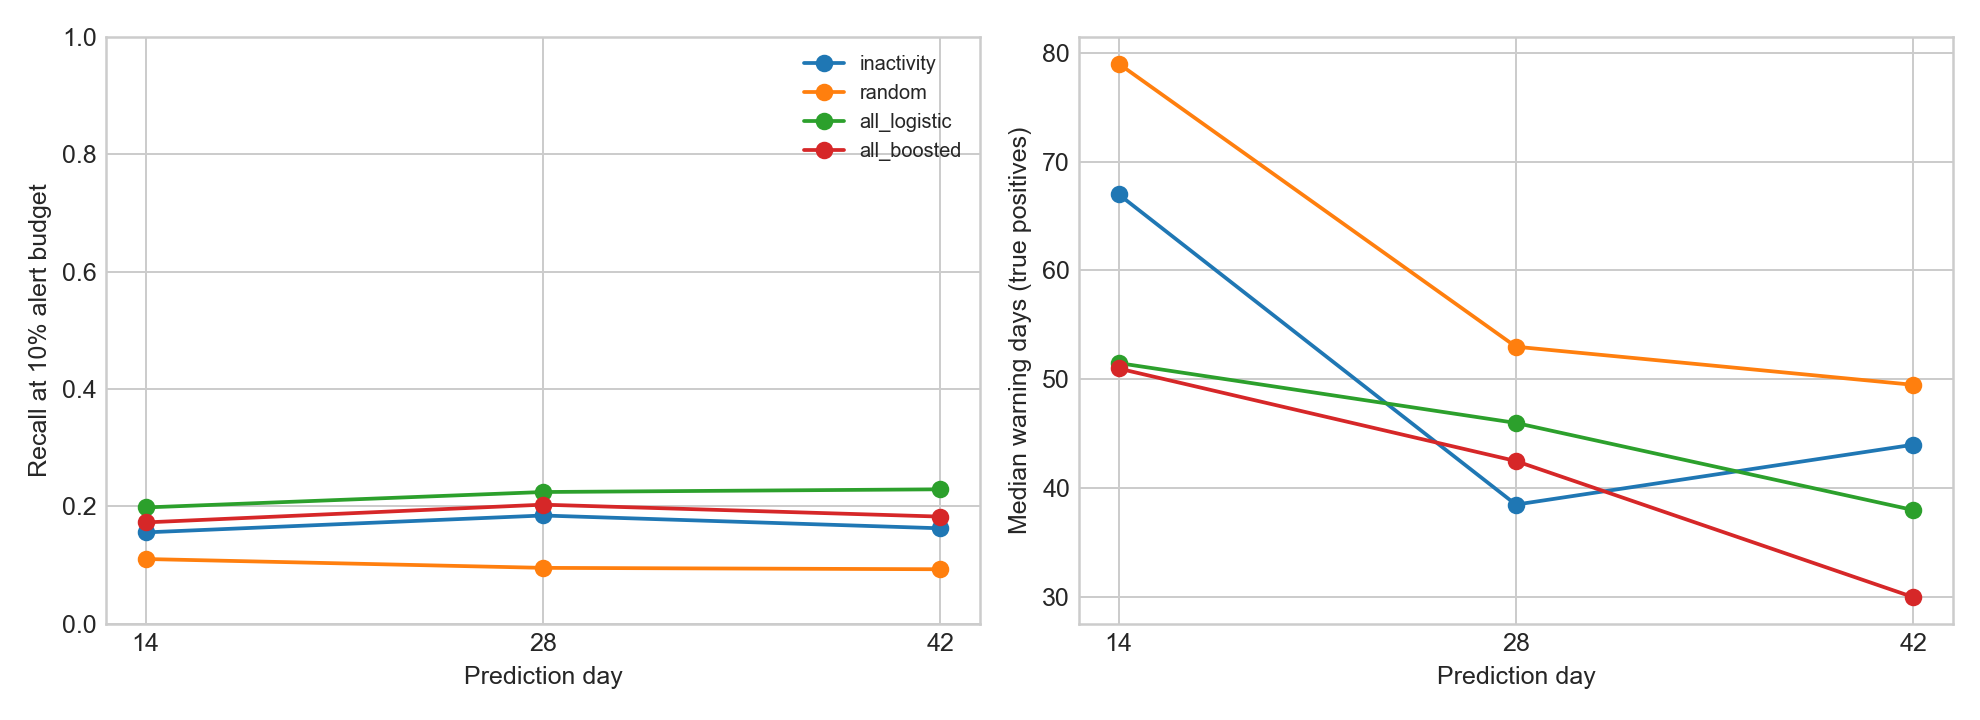

In [2]:
display(pd.read_csv(R / 'cohorts.csv'))
display(pd.read_csv(R / 'primary_results.csv').round(3))
display(Image(filename=str(R / 'figures' / 'early_warning_tradeoff.png')))

## Graduate analysis: common cohort, ablations, uncertainty

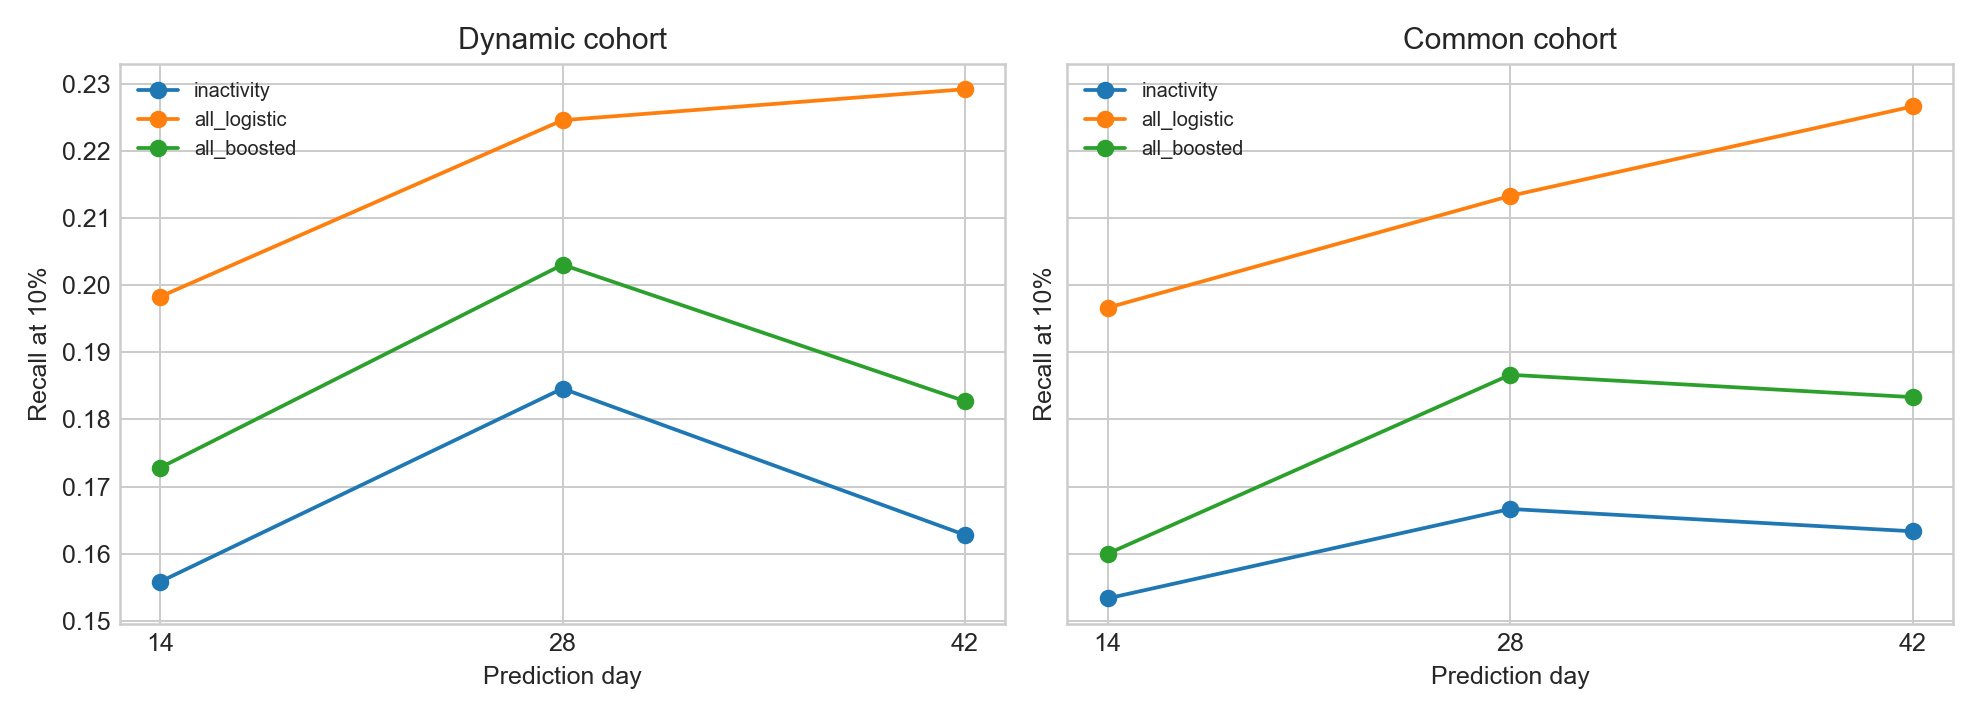

cutoff,14,28,42
model,,,
all_boosted,0.173,0.203,0.183
all_logistic,0.198,0.225,0.229
background_boosted,0.170,0.182,0.173
background_logistic,0.176,0.191,0.183
engagement_boosted,0.127,0.166,0.153
engagement_logistic,0.176,0.166,0.163
engagement_submission_boosted,0.133,0.191,0.193
engagement_submission_logistic,0.178,0.206,0.206
inactivity,0.156,0.185,0.163


,cutoff,population,model,baseline,metric,difference,ci_low,ci_high,valid_replicates
0,14,dynamic,all_logistic,inactivity,recall_at_10pct,0.042,0.005,0.087,2000
1,14,dynamic,all_logistic,inactivity,precision_at_10pct,0.081,0.011,0.167,2000
2,14,dynamic,all_logistic,inactivity,average_precision,0.077,0.043,0.116,2000
3,14,common,all_logistic,inactivity,recall_at_10pct,0.043,-0.007,0.088,2000
4,14,common,all_logistic,inactivity,precision_at_10pct,0.072,-0.011,0.144,2000
5,14,common,all_logistic,inactivity,average_precision,0.055,0.024,0.092,2000
6,14,dynamic,all_boosted,inactivity,recall_at_10pct,0.017,-0.024,0.051,2000
7,14,dynamic,all_boosted,inactivity,precision_at_10pct,0.032,-0.048,0.097,2000
8,14,dynamic,all_boosted,inactivity,average_precision,0.061,0.031,0.099,2000
9,14,common,all_boosted,inactivity,recall_at_10pct,0.007,-0.037,0.049,2000


In [3]:
display(Image(filename=str(R / 'figures' / 'common_cohort.png')))
metrics = pd.read_csv(R / 'metrics.csv')
display(metrics.loc[metrics.population.eq('dynamic')].pivot(index='model',columns='cutoff',values='recall_at_10pct').round(3))
display(pd.read_csv(R / 'paired_bootstrap.csv').round(3))

## Explore the outreach budget
Change day, cohort, and budget to see how many withdrawals are identified and how many alerts are false positives. The primary protocol remains 10%. Other budgets are retrospective sensitivity analyses with fixed scores. Aggregate results for every integer budget from 5% through 20% are saved in `results/budget_sensitivity.csv`.

In [4]:
from withdrawal.submission import explore
import ipywidgets as widgets
def show_budget(day=28, population='dynamic', budget=10):
    table = explore(day, population, budget)
    table['false_alerts'] = table.alerts - table.true_positives
    display(table[['model','alerts','true_positives','false_alerts','recall_at_10pct','precision_at_10pct','median_warning_days']].rename(columns={'recall_at_10pct':'recall','precision_at_10pct':'precision'}).round(3))
show_budget()
controls = widgets.interactive(show_budget, day=widgets.Dropdown(options=[14,28,42], value=28), population=widgets.Dropdown(options=['dynamic','common']), budget=widgets.IntSlider(min=5,max=20,step=1,value=10,description='Budget %'))
display(controls)

,model,alerts,true_positives,false_alerts,recall,precision,median_warning_days
0,inactivity,183,60,123,0.185,0.328,38.5
1,random,183,31,152,0.095,0.169,53.0
2,all_logistic,183,73,110,0.225,0.399,46.0
3,all_boosted,183,66,117,0.203,0.361,42.5


## Error audit
Cases are selected by the median predicted score within each error group, using fixed tie order. These observed features do not establish the cause of a withdrawal.

In [5]:
display(pd.read_csv(R / 'error_analysis.csv').round(3))
display(pd.read_csv(R / 'error_examples.csv').round(3))

,error_type,num_of_prev_attempts,studied_credits,total_clicks,active_days,days_since_last_activity,no_activity,clicks_last_7,clicks_previous_7,click_change,submissions,assignments_due,overdue,submission_rate,warning_days,count,cutoff,model
0,false_positive,0.0,120.0,65.5,4.0,4.5,0.0,3.5,10.5,0.0,0.0,0.0,0.0,NaN,NaN,116,14,all_logistic
1,missed_withdrawal,0.0,60.0,209.0,10.0,1.0,0.0,40.0,55.0,-8.0,0.0,0.0,0.0,NaN,81.0,283,14,all_logistic
2,true_negative,0.0,60.0,305.0,12.0,1.0,0.0,87.0,102.0,-6.0,0.0,0.0,0.0,NaN,NaN,1393,14,all_logistic
3,true_positive,0.0,120.0,93.5,6.0,3.0,0.0,11.0,33.5,-1.0,0.0,0.0,0.0,NaN,51.5,70,14,all_logistic
4,false_positive,0.0,120.0,52.0,5.0,6.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,NaN,NaN,125,14,all_boosted
5,missed_withdrawal,0.0,60.0,208.5,9.0,1.0,0.0,39.5,56.0,-13.5,0.0,0.0,0.0,NaN,80.0,292,14,all_boosted
6,true_negative,0.0,60.0,305.0,12.0,1.0,0.0,88.0,102.0,-8.0,0.0,0.0,0.0,NaN,NaN,1384,14,all_boosted
7,true_positive,0.0,120.0,66.0,4.0,5.0,0.0,7.0,3.0,0.0,0.0,0.0,0.0,NaN,51.0,61,14,all_boosted
8,false_positive,0.0,105.0,94.0,6.0,5.5,0.0,1.0,5.5,0.0,0.0,1.0,1.0,0.0,NaN,110,28,all_logistic
9,missed_withdrawal,0.0,60.0,438.0,17.0,1.0,0.0,78.0,85.5,-2.0,1.0,1.0,0.0,1.0,72.0,252,28,all_logistic


,cutoff,model,error_type,id_student,predicted_probability,final_result,warning_days,num_of_prev_attempts,studied_credits,highest_education,...,active_days,days_since_last_activity,no_activity,clicks_last_7,clicks_previous_7,click_change,submissions,assignments_due,overdue,submission_rate
0,14,all_logistic,false_positive,1866233,0.288,Fail,NaN,1,60,A Level or Equivalent,...,0,60.0,1,0,0,0,0,0,0,NaN
1,14,all_logistic,missed_withdrawal,698762,0.158,Withdrawn,60.0,0,120,A Level or Equivalent,...,12,2.0,0,173,80,93,0,0,0,NaN
2,14,all_boosted,false_positive,372511,0.309,Pass,NaN,0,150,HE Qualification,...,1,7.0,0,0,1,-1,0,0,0,NaN
3,14,all_boosted,missed_withdrawal,676040,0.151,Withdrawn,48.0,0,60,Lower Than A Level,...,12,1.0,0,62,118,-56,0,0,0,NaN
4,28,all_logistic,false_positive,679790,0.315,Pass,NaN,0,120,HE Qualification,...,8,0.0,0,23,20,3,0,1,1,0.0
5,28,all_logistic,missed_withdrawal,695250,0.142,Withdrawn,72.0,0,120,A Level or Equivalent,...,26,1.0,0,99,323,-224,1,1,0,1.0
6,28,all_boosted,false_positive,652647,0.311,Fail,NaN,0,90,Lower Than A Level,...,24,0.0,0,48,156,-108,0,1,1,0.0
7,28,all_boosted,missed_withdrawal,631193,0.142,Withdrawn,13.0,0,120,Lower Than A Level,...,15,2.0,0,88,0,88,1,1,0,1.0
8,42,all_logistic,false_positive,650048,0.254,Fail,NaN,0,120,Lower Than A Level,...,4,19.0,0,0,0,0,1,1,0,1.0
9,42,all_logistic,missed_withdrawal,340831,0.141,Withdrawn,27.0,0,120,A Level or Equivalent,...,32,1.0,0,1,67,-66,1,1,0,1.0


## AI use and references

In [6]:
display(Markdown((ROOT / 'docs' / 'AI_USE_AND_REFERENCES.md').read_text(encoding='utf-8')))

# AI use, data attribution and external sources

## Disclosure

AI tools, including OpenAI Codex, were used during this project. All reported results were computed from the OULAD experiments.

## Sources and software

1. Kuzilek, J., Hlosta, M., and Zdrahal, Z. (2017). *Open University Learning Analytics dataset*. Scientific Data 4, 170171. https://doi.org/10.1038/sdata.2017.171 — dataset description and schema.
2. Kuzilek, J., Hlosta, M., and Zdrahal, Z. (2015). *Open University Learning Analytics dataset*. UCI Machine Learning Repository. https://doi.org/10.24432/C5KK69 — downloaded archive, CC BY 4.0 license: https://creativecommons.org/licenses/by/4.0/ . Snapshot, split and prediction files are derived transformations; original authors retain attribution.
3. Pedregosa, F., et al. (2011). *Scikit-learn: Machine Learning in Python*. Journal of Machine Learning Research 12, 2825–2830. https://jmlr.org/papers/v12/pedregosa11a.html — model, preprocessing, CV and metrics implementations. Version 1.6 documentation: https://scikit-learn.org/1.6/ .
4. pandas: https://pandas.pydata.org/docs/ ; NumPy: https://numpy.org/doc/ ; SciPy: https://docs.scipy.org/doc/scipy/ — tabular/numerical operations and model runtime.
5. Matplotlib: https://matplotlib.org/stable/ ; Jupyter: https://jupyter.org/ ; ipywidgets: https://ipywidgets.readthedocs.io/ — figures, notebook and interactive result explorer.
6. OpenAI Codex: https://openai.com/codex/ — AI assistance as disclosed above; not a scientific source supporting empirical claims.
